# NoFlyZone: Initial Exploration and Baseline Models
### CIS4930 - Introduction to Machine Learning | Term project

**Question:** How well can passenger context and service ratings classify `liked` for unseen survey profiles?

Explore the data, prepare consistent training and validation partitions, and compare four starting models. The source defines `liked=1` as overall satisfaction of 4 or 5. Service ratings come from the same survey, so this is retrospective classification.

Run this notebook from the project folder using the `noflyzone` environment. Results stay in the notebook. The completed study is in `NoFlyZone.ipynb`.

## 1. Data and source

[Real Airline Passenger Satisfaction Dataset, Rustam32 on Kaggle](https://www.kaggle.com/datasets/rustam32/real-airline-passenger-satisfaction-dataset), based on [Brazil Ministry of Transport airport passenger surveys](https://dados.transportes.gov.br/dataset/pesquisa-de-satisfacao-do-passageiro-em-aeroportos).

The data card reports keeping 28,757 negative responses and randomly selecting the same number of positive responses. This balances the file by undersampling the positive class. Time fields are in seconds; `*_is_applicable` flags indicate whether a question applies (1) or does not apply (0). The listed license is MIT.

The upstream build script, collection years, airport coverage, and original positive prevalence have not been independently audited. Counts and experiment results below come from the supplied CSV.

Use the `noflyzone` Conda environment and run the notebook from this folder. `project_support.py` supplies the feature transformers.

In [1]:
from pathlib import Path
import os
import sys

# Make Conda's numerical libraries available on Windows.
if os.name == 'nt' and (Path(sys.prefix) / 'Library/bin').exists():
    _conda_dll = os.add_dll_directory(str(Path(sys.prefix) / 'Library/bin'))
    os.environ['PATH'] = str(Path(sys.prefix) / 'Library/bin') + os.pathsep + os.environ['PATH']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
from project_support import SurveyFeatures, QuantileClipper

SEED = 42
np.random.seed(SEED)
threadpool_limits(limits=4)
sns.set_theme(style='whitegrid', context='notebook', palette=['#147D92', '#DA8046'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot():
    plt.tight_layout()
    plt.show()
    plt.close('all')

raw = pd.read_csv('passenger_survey_balanced.csv')
assert raw.columns.is_unique and raw['liked'].notna().all()
assert set(raw['liked'].unique()) == {0, 1}
print(f'{raw.shape[0]:,} rows, {raw.shape[1]} columns')
display(raw.head())

57,514 rows, 145 columns


,process,month,flight_type,connection,ticket_purchased_by,ticket_purchase_channel,transport_to_airport,has_disability,uses_assistive_device,requested_special_assistance,...,restrooms_is_applicable,restroom_quantity_is_applicable,restroom_cleanliness_is_applicable,restroom_maintenance_is_applicable,baggage_claim_process_is_applicable,baggage_carousel_identification_ease_is_applicable,baggage_claim_time_is_applicable,baggage_integrity_is_applicable,arrival_lead_time_is_applicable,connection_wait_time_is_applicable
0,Boarding,October,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride from someone,No,Not applicable,Not applicable,...,1,0,0,0,0,0,0,0,1,0
1,Boarding,March,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride-hailing app,No,Not applicable,Not applicable,...,1,0,0,0,0,0,0,0,1,0
2,Disembarkation,January,Domestic,Not applicable,Not applicable,Not applicable,Not applicable,No,Not applicable,Not applicable,...,0,0,0,0,1,0,0,0,0,0
3,Boarding,August,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride-hailing app,No,Not applicable,Not applicable,...,1,1,1,1,0,0,0,0,1,0
4,Boarding,February,Domestic,Boarded at the airport,By the passenger,Travel agency/third-party website,Bus,No,Not applicable,Not applicable,...,1,0,0,0,0,0,0,0,1,0


Loaded **57,514 rows × 145 columns** (144 candidate predictors).

In [2]:
dictionary = pd.DataFrame({'feature': raw.columns, 'dtype': raw.dtypes.astype(str).values,
    'non_null': raw.notna().sum().values, 'missing_pct': raw.isna().mean().values * 100,
    'unique_non_null': raw.nunique().values})
dictionary['role'] = np.where(dictionary.feature.eq('liked'), 'binary target',
    np.where(dictionary.feature.str.endswith('_is_applicable'), 'applicability indicator',
    np.where(dictionary.dtype.eq('object'), 'categorical context', 'numeric survey field')))
display(dictionary.head(15))
display(raw.describe().T.head(15))

,feature,dtype,non_null,missing_pct,unique_non_null,role
0,process,object,57514,0.000000,2,categorical context
1,month,object,57514,0.000000,12,categorical context
2,flight_type,object,57514,0.000000,2,categorical context
3,connection,object,57514,0.000000,3,categorical context
4,ticket_purchased_by,object,57514,0.000000,3,categorical context
5,ticket_purchase_channel,object,41374,28.062733,12,categorical context
6,transport_to_airport,object,57513,0.001739,16,categorical context
7,has_disability,object,57514,0.000000,5,categorical context
8,uses_assistive_device,object,55813,2.957541,11,categorical context
9,requested_special_assistance,object,56487,1.785652,11,categorical context


,count,mean,std,min,25%,50%,75%,max
disembarkation_method_rating,330.0,3.739394,1.171583,1.0,3.0,4.0,5.0,5.0
curbside_dropoff_ease,20958.0,4.131215,0.953496,1.0,4.0,4.0,5.0,5.0
transport_options_to_airport,16829.0,3.807832,1.055072,1.0,3.0,4.0,5.0,5.0
checkin_process,8489.0,4.075745,1.122362,1.0,4.0,4.0,5.0,5.0
checkin_queue_wait_time,1843.0,2.670646,1.305023,1.0,1.5,3.0,4.0,5.0
checkin_queue_organization,1822.0,2.875412,1.276820,1.0,2.0,3.0,4.0,5.0
self_service_kiosk_quantity,340.0,3.220588,1.142445,1.0,2.0,3.0,4.0,5.0
checkin_counter_quantity,1582.0,2.665613,1.239787,1.0,2.0,3.0,4.0,5.0
staff_courtesy,1587.0,3.615627,1.196762,1.0,3.0,4.0,4.0,5.0
checkin_service_time,1587.0,3.293636,1.251271,1.0,2.0,4.0,4.0,5.0


## 2. Classification problem

- **Target:** `liked`, a binary satisfaction label for each survey record.
- **Main comparison:** validation macro F1, which gives both classes equal weight. Accuracy, positive-class precision/recall, and ROC-AUC provide additional context.
- **Splits:** keep identical modeled profiles together in approximately 60% training, 20% validation, and 20% test. This notebook uses training and validation; the test partition is reserved here for the completed study.
- **Predictors:** exclude eight demographic/assistance fields. Remaining variables may still contain proxies, so this does not establish fairness.

## 3. Data integrity and exploratory analysis

We inspect whole-file schema, label counts, and duplicates to define the evaluation population. Feature/label relationship plots and modeling choices use the training partition only. Exact repeated rows are removed because their origin is unknown; identical predictors with conflicting labels are retained and assigned to the same split. This changes the target population to unique survey records and does not recover the original population prevalence.

,split,rows,positive_rate,unique_profiles
0,train,26171,0.448626,24651
1,validation,8787,0.444976,8273
2,test,8823,0.445540,8278


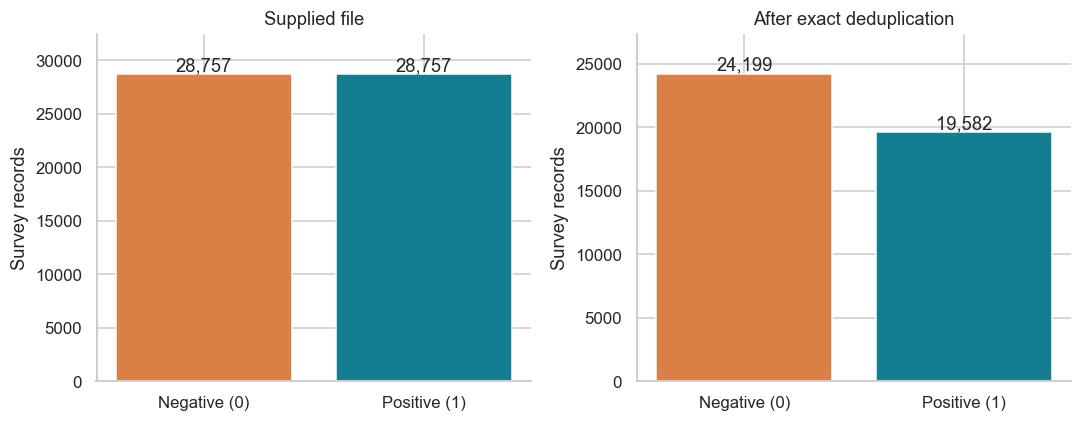

In [3]:
duplicate_count = int(raw.duplicated().sum())
data = raw.drop_duplicates().copy()
data.insert(0, 'source_row', data.index)
data.reset_index(drop=True, inplace=True)
TARGET = 'liked'
SENSITIVE = ['gender', 'age_group', 'nationality', 'education', 'household_income',
             'has_disability', 'uses_assistive_device', 'requested_special_assistance']
X = data.drop(columns=[TARGET, 'source_row'] + SENSITIVE)
y = data[TARGET].astype(int)
# Group by model inputs, so profiles made identical by demographic exclusion stay together.
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
conflicts = pd.DataFrame({'group': groups, 'y': y}).groupby('group').y.nunique()
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(X, y, groups))
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
a, b = next(inner.split(X.iloc[dev_idx], y.iloc[dev_idx], groups.iloc[dev_idx]))
train_idx, val_idx = dev_idx[a], dev_idx[b]
X_train, X_val, X_test = [X.iloc[ix].copy() for ix in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = [y.iloc[ix].copy() for ix in [train_idx, val_idx, test_idx]]
g_train, g_val, g_test = [groups.iloc[ix] for ix in [train_idx, val_idx, test_idx]]
assert not (set(g_train) & set(g_val) or set(g_train) & set(g_test) or set(g_val) & set(g_test))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(data)
split_summary = pd.DataFrame([{'split': n, 'rows': len(ix), 'positive_rate': y.iloc[ix].mean(),
    'unique_profiles': groups.iloc[ix].nunique()} for n, ix in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]])
display(split_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, frame, title in zip(axes, [raw, data], ['Supplied file', 'After exact deduplication']):
    counts = frame.liked.value_counts().sort_index()
    ax.bar(['Negative (0)', 'Positive (1)'], counts, color=['#DA8046','#147D92'])
    ax.set(title=title, ylabel='Survey records')
    ax.set_ylim(0, counts.max() * 1.13)
    for i, v in enumerate(counts): ax.text(i, v + 300, f'{v:,}', ha='center')
show_plot()

**13,733 exact duplicates removed**; **43,781 records retained**. 881 modeled feature profiles have conflicting labels. The retained positive share is **44.7%**. No modeled profile overlaps splits.

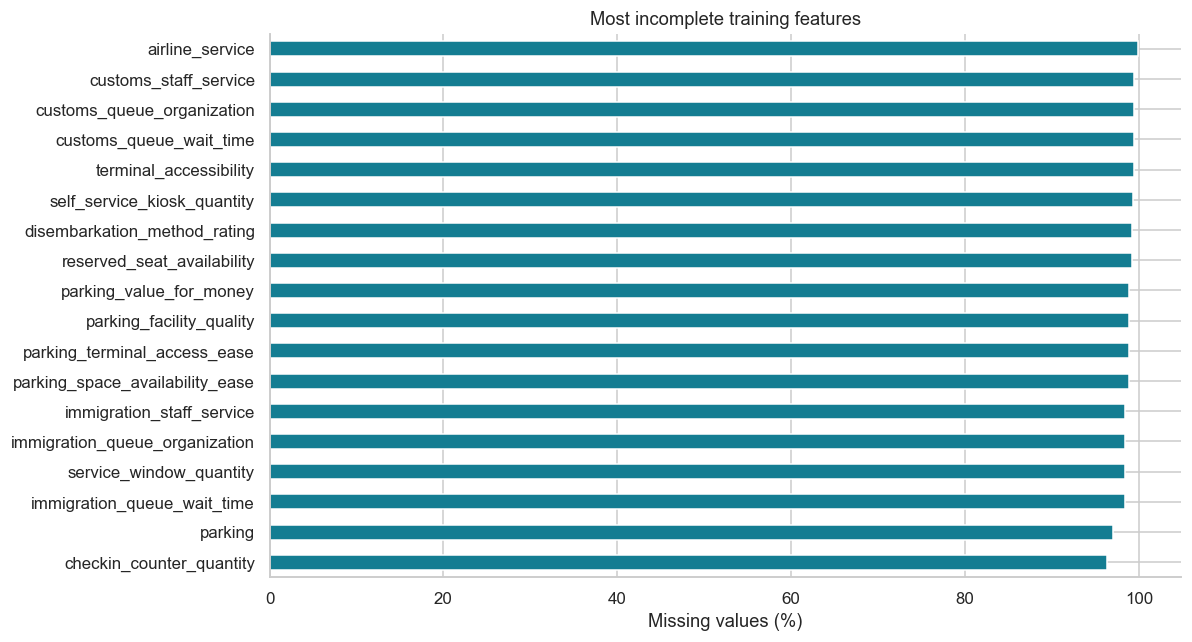

,feature,missing_fraction
0,airline_service,0.998854
1,customs_staff_service,0.994536
2,customs_queue_organization,0.994383
3,customs_queue_wait_time,0.994268
4,terminal_accessibility,0.994077
...,...,...
131,baggage_carousel_identification_ease_is_applic...,0.000000
132,baggage_claim_time_is_applicable,0.000000
133,baggage_integrity_is_applicable,0.000000
134,arrival_lead_time_is_applicable,0.000000


,feature,observed,minimum,maximum,invalid_outside_1_5
0,disembarkation_method_rating,196,1.0,5.0,0
1,curbside_dropoff_ease,12485,1.0,5.0,0
2,transport_options_to_airport,10044,1.0,5.0,0
3,checkin_process,5028,1.0,5.0,0
4,checkin_queue_wait_time,1116,1.0,5.0,0
5,checkin_queue_organization,1097,1.0,5.0,0
6,self_service_kiosk_quantity,187,1.0,5.0,0
7,checkin_counter_quantity,963,1.0,5.0,0
8,staff_courtesy,967,1.0,5.0,0
9,checkin_service_time,966,1.0,5.0,0


,feature,applicable_but_missing,not_applicable_but_observed
28,retail_outlets,16409,0
46,airport_internet,14969,0
3,checkin_process,14844,0
24,food_beverage_outlets,10706,0
2,transport_options_to_airport,9828,0
10,ticket_purchase_process,9691,0
1,curbside_dropoff_ease,7387,0
12,security_screening_process,6614,0
49,restrooms,6367,0
45,power_outlet_availability,5513,0


In [4]:
train_data = data.iloc[train_idx]
missing = X_train.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
missing.head(18).sort_values().mul(100).plot.barh(ax=ax, color='#147D92')
ax.set(xlabel='Missing values (%)', title='Most incomplete training features')
show_plot()
display(pd.DataFrame({'feature':missing.index, 'missing_fraction':missing.values}))

TIME_COLS = ['arrival_lead_time', 'connection_wait_time']
RATINGS = [c for c in X.select_dtypes('number') if c not in TIME_COLS and not c.endswith('_is_applicable')]
FLAGS = [c for c in X if c.endswith('_is_applicable')]
rating_audit = pd.DataFrame([{'feature':c, 'observed':int(X_train[c].notna().sum()),
    'minimum':X_train[c].min(), 'maximum':X_train[c].max(),
    'invalid_outside_1_5':int((X_train[c].notna() & ~X_train[c].between(1,5)).sum())} for c in RATINGS])
display(rating_audit.head(10))
assert rating_audit.invalid_outside_1_5.sum() == 0
applicability_audit = []
for flag in FLAGS:
    base = flag.removesuffix('_is_applicable')
    applicability_audit.append({'feature':base,
        'applicable_but_missing':int(((X_train[flag]==1) & X_train[base].isna()).sum()),
        'not_applicable_but_observed':int(((X_train[flag]==0) & X_train[base].notna()).sum())})
display(pd.DataFrame(applicability_audit).sort_values('applicable_but_missing', ascending=False).head(10))

**Missing is not the same as dissatisfied.** Many questions only apply to one journey stage or a particular service. We retain source applicability flags, add missingness indicators, and median-impute ratings inside each training fold. Literal “Not applicable” categorical answers remain a distinct category; actual missing categorical values use a separate token.

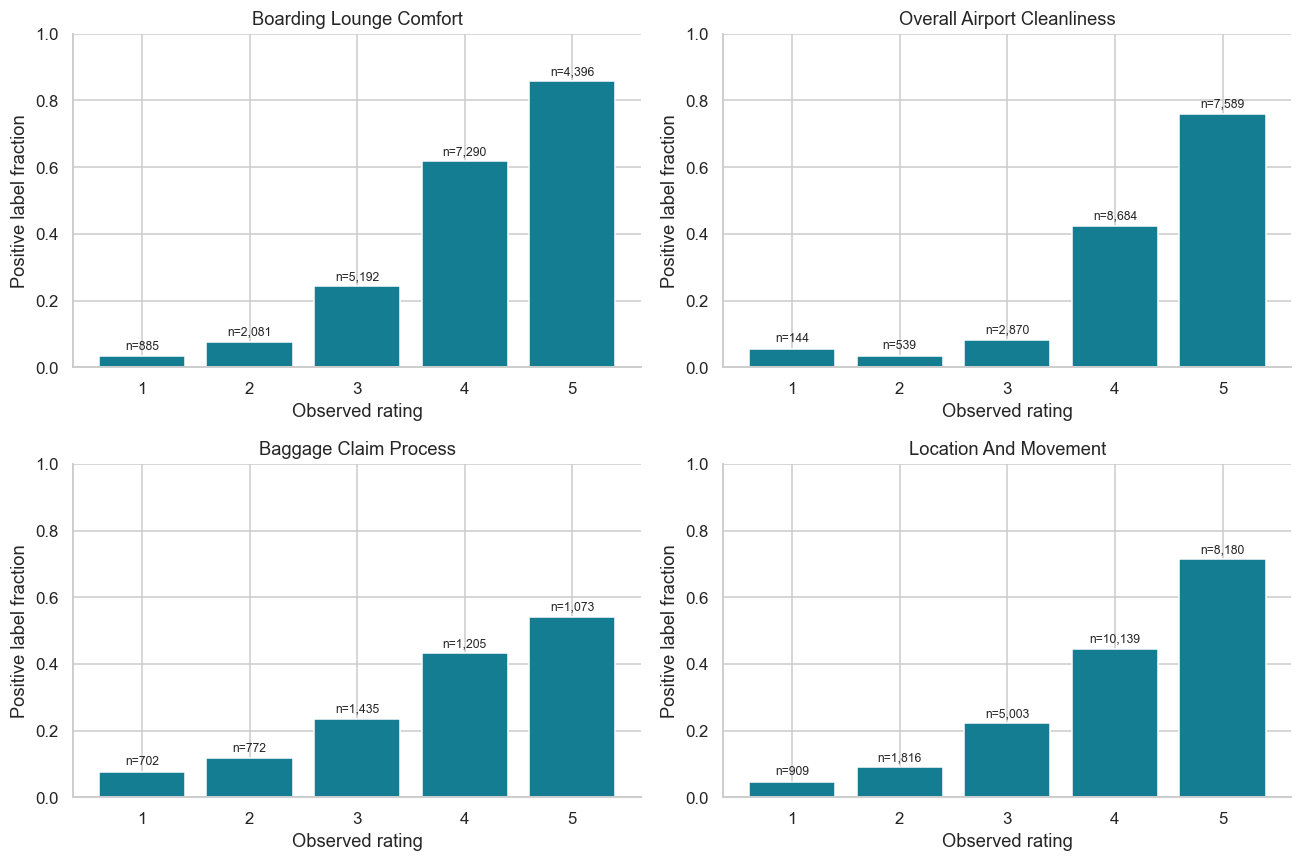

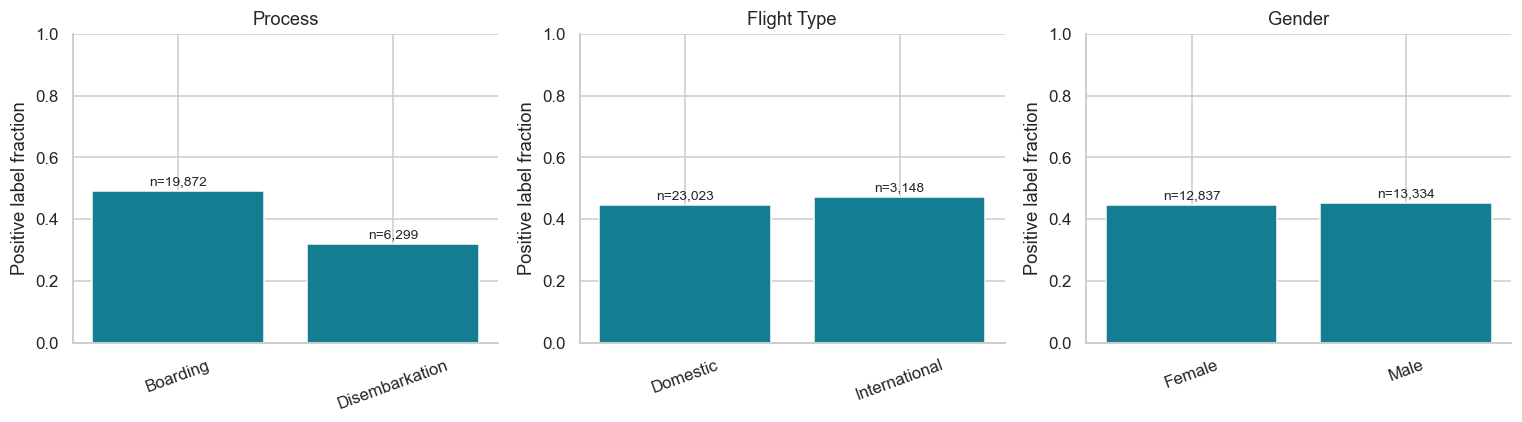

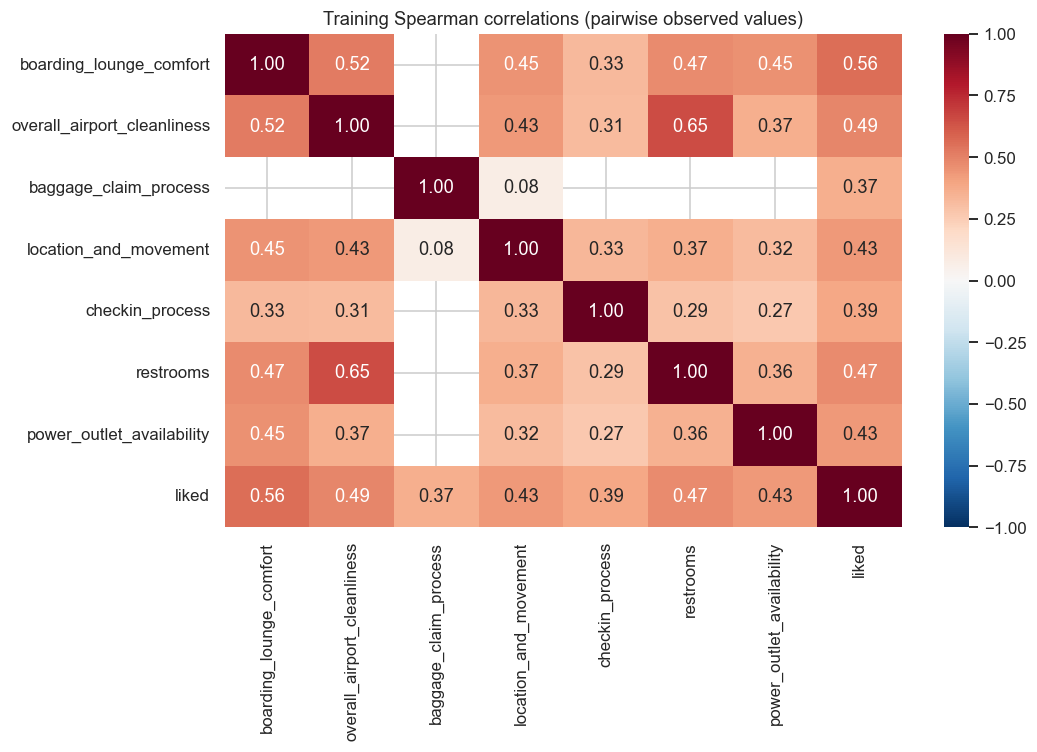

In [5]:
selected_ratings = ['boarding_lounge_comfort','overall_airport_cleanliness','baggage_claim_process','location_and_movement']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.flat, selected_ratings):
    tmp = train_data.groupby(c).liked.agg(['mean','count']).reset_index()
    ax.bar(tmp[c], tmp['mean'], color='#147D92')
    ax.set(title=c.replace('_',' ').title(), xlabel='Observed rating', ylabel='Positive label fraction', ylim=(0,1))
    for _, r in tmp.iterrows(): ax.text(r[c], r['mean'] + .02, f"n={int(r['count']):,}", ha='center', fontsize=8)
show_plot()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ['process','flight_type','gender']):
    tmp = train_data.groupby(c).liked.agg(['mean','count']).reset_index()
    ax.bar(tmp[c], tmp['mean'], color='#147D92')
    ax.set(title=c.replace('_',' ').title(), ylabel='Positive label fraction', ylim=(0,1))
    ax.tick_params(axis='x', labelrotation=20)
    for j, r in tmp.iterrows(): ax.text(j, r['mean'] + .02, f"n={int(r['count']):,}", ha='center', fontsize=9)
show_plot()

corr_columns = selected_ratings + ['checkin_process','restrooms','power_outlet_availability','liked']
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(train_data[corr_columns].corr(method='spearman', min_periods=100), annot=True,
    fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Training Spearman correlations (pairwise observed values)')
show_plot()

Higher recorded service ratings tend to accompany a positive label in these training plots. Each bar uses only respondents with an observed rating; sample sizes differ. Pairwise correlations can reflect different respondent subsets and do not establish cause. The source defines `liked` from a separate overall-satisfaction answer that is absent from the predictors; remaining service ratings are contemporaneous self-reports, so shared response tendencies remain possible.

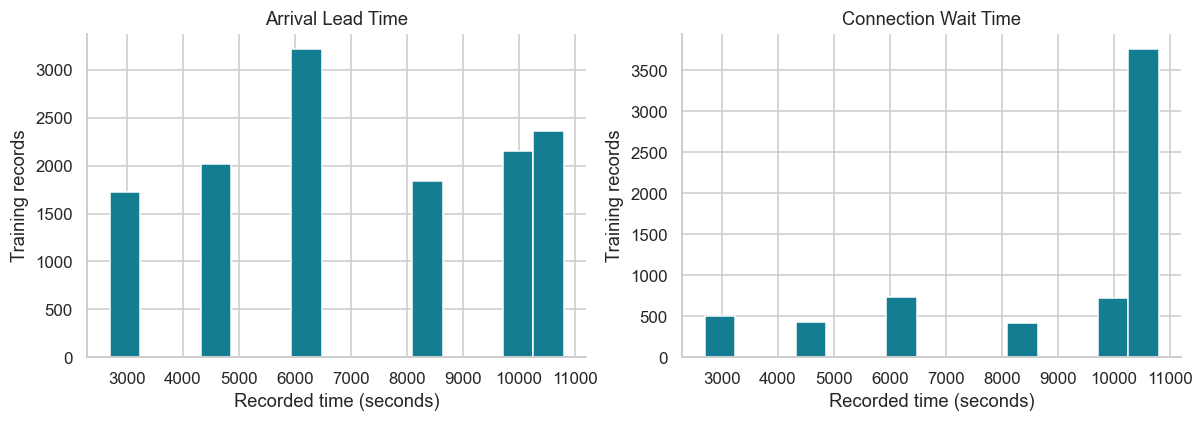

,feature,q1,q3,iqr,outside_iqr,q01,q99
0,arrival_lead_time,4500.0,9900.0,5400.0,0,2700.0,10800.0
1,connection_wait_time,6300.0,10800.0,4500.0,0,2700.0,10800.0


In [6]:
outliers=[]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, TIME_COLS):
    values=X_train[c].dropna(); q1,q3=values.quantile([.25,.75]); iqr=q3-q1
    outliers.append({'feature':c,'q1':q1,'q3':q3,'iqr':iqr,
        'outside_iqr':int(((values<q1-1.5*iqr)|(values>q3+1.5*iqr)).sum()),
        'q01':values.quantile(.01),'q99':values.quantile(.99)})
    ax.hist(values,bins=15,color='#147D92')
    ax.set(title=c.replace('_',' ').title(), xlabel='Recorded time (seconds)', ylabel='Training records')
show_plot()
display(pd.DataFrame(outliers))

The source documents these time fields in seconds. They have a small number of distinct coded values; we retain their original units. Training-fitted 1st/99th-percentile clipping is applied only to these fields. The audit may show that it changes no values. Valid 1–5 ordinal ratings and binary flags are never winsorized; rare valid answers are preserved.

## 4. Prepare the predictors

Use the same preprocessing as the completed notebook so the starting models are comparable. All fitted transformations learn from training data only.

- Median-impute numeric features, add missingness indicators, and standardize.
- Clip time fields at training-derived 1st/99th percentiles.
- Impute and one-hot encode categorical responses, pooling rare training categories.
- Add each row's mean rating, rating count, and low-rating fraction; remove constant encoded columns.

In [7]:
def make_pipeline(model, columns=None, engineered=True):
    cols = list(X_train.columns if columns is None else columns)
    rating_cols = tuple(c for c in RATINGS if c in cols)
    times = [c for c in TIME_COLS if c in cols]
    num = [c for c in cols if pd.api.types.is_numeric_dtype(X_train[c]) and c not in times]
    cats = [c for c in cols if c not in num + times]
    if engineered and rating_cols:
        num += ['rating_mean','rating_count','low_rating_fraction']
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                        ('scale', StandardScaler())])
    timed = Pipeline([('clip', QuantileClipper()), ('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                      ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='__MISSING__')),
        ('encode', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False))])
    preprocess = ColumnTransformer([('numeric', numeric, num), ('time', timed, times), ('categorical', categorical, cats)], remainder='drop')
    return Pipeline([('features', SurveyFeatures(rating_cols, enabled=bool(engineered and rating_cols))),
        ('preprocess', preprocess), ('constant_filter', VarianceThreshold()), ('model', model)])

## 5. Fit the starting models

Compare a majority-class baseline, logistic regression, a decision tree, and KNN. These use the fixed starting settings from the completed notebook. Each model fits the entire training partition and predicts the same validation partition.

The majority baseline checks whether learning adds value. Logistic regression provides a linear comparison; the tree captures interactions; KNN uses similarity between preprocessed responses. Training macro F1 helps identify overfitting.

In [8]:
models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': LogisticRegression(max_iter=1500, C=1, random_state=SEED),
    'Decision tree': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=21, weights='distance', n_jobs=1),
}
fitted_models = {}
rows = []
for name, estimator in models.items():
    print('Fitting:', name, flush=True)
    model = make_pipeline(estimator).fit(X_train, y_train)
    fitted_models[name] = model
    train_prediction = model.predict(X_train)
    prediction = model.predict(X_val)
    probability = model.predict_proba(X_val)[:, 1]
    rows.append({
        'model': name,
        'train_macro_f1': f1_score(y_train, train_prediction, average='macro'),
        'validation_macro_f1': f1_score(y_val, prediction, average='macro'),
        'validation_accuracy': accuracy_score(y_val, prediction),
        'validation_precision': precision_score(y_val, prediction, zero_division=0),
        'validation_recall': recall_score(y_val, prediction, zero_division=0),
        'validation_roc_auc': roc_auc_score(y_val, probability),
    })
results = pd.DataFrame(rows)
results['train_validation_gap'] = results.train_macro_f1 - results.validation_macro_f1
results = results.sort_values('validation_macro_f1', ascending=False).reset_index(drop=True)
display(results.round(4))

Fitting: Majority baseline


Fitting: Logistic regression


Fitting: Decision tree


Fitting: KNN


,model,train_macro_f1,validation_macro_f1,validation_accuracy,validation_precision,validation_recall,validation_roc_auc,train_validation_gap
0,Logistic regression,0.8320,0.8292,0.8309,0.8024,0.8225,0.9076,0.0028
1,KNN,0.9706,0.8136,0.8155,0.7866,0.8033,0.8936,0.1570
2,Decision tree,0.8467,0.8092,0.8113,0.7854,0.7926,0.8846,0.0375
3,Majority baseline,0.3554,0.3569,0.5550,0.0000,0.0000,0.5000,-0.0015


### Initial results

Logistic regression leads these four models with validation macro F1 **0.8292** and accuracy **83.09%**, compared with majority-baseline macro F1 **0.3569**. KNN reaches **0.8136** and the decision tree **0.8092** macro F1. These are validation comparisons, not final test results.

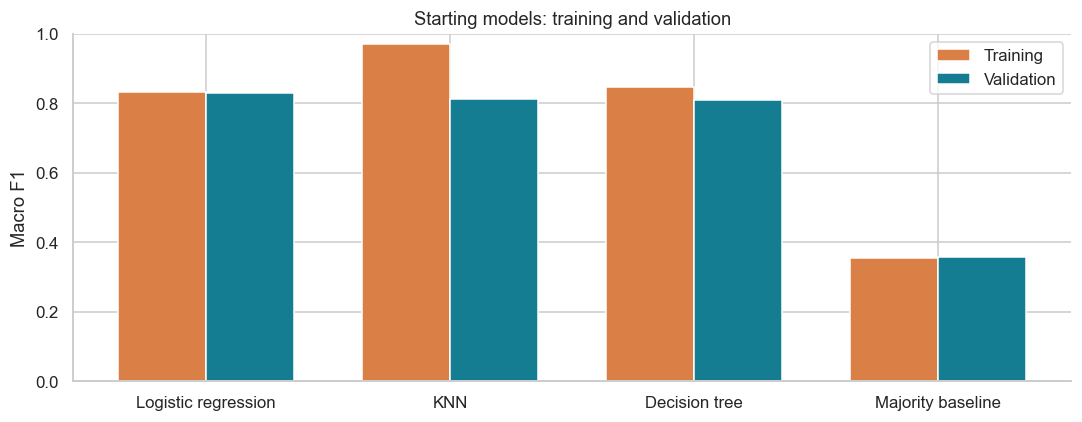

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(len(results))
ax.bar(positions - 0.18, results.train_macro_f1, width=0.36, label='Training', color='#DA8046')
ax.bar(positions + 0.18, results.validation_macro_f1, width=0.36, label='Validation', color='#147D92')
ax.set_xticks(positions, results.model)
ax.set(ylabel='Macro F1', ylim=(0, 1), title='Starting models: training and validation')
ax.legend()
show_plot()

KNN has the largest training/validation gap (**0.1570**): its training macro F1 is **0.9706**, but validation falls to **0.8136**. The tree's gap is **0.0375**, while logistic regression's is **0.0028**. KNN's strong training fit does not carry over as well to unseen profiles.

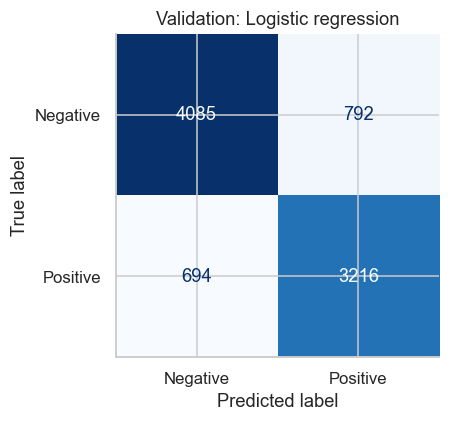

In [10]:
best_name = results.iloc[0]['model']
best_prediction = fitted_models[best_name].predict(X_val)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_val, best_prediction, display_labels=['Negative', 'Positive'],
    cmap='Blues', colorbar=False, ax=ax,
)
ax.set_title(f'Validation: {best_name}')
show_plot()

For logistic regression, positive-class precision is **0.8024** and recall is **0.8225**. The off-diagonal counts show both types of error: negative experiences predicted positive, and positive experiences predicted negative.

## 6. Next Steps

1. **Check stability:** compare models with grouped cross-validation rather than relying only on one validation split.
2. **Reduce overfitting:** tune KNN's neighbor count and weighting; tune tree depth and minimum leaf size. Compare validation scores and training gaps.
3. **Test the features:** compare results with and without rating aggregates, then try a context-only model to measure dependence on same-survey service ratings.
4. **Try ensembles:** compare random forest and boosting with the logistic baseline before adding more complex models.
5. **Inspect errors:** examine which survey profiles and sufficiently represented subgroups account for mistakes. Choose any decision threshold using validation data.
